In [1]:
from langchain_core.runnables import RunnableConfig
from typing import List, Optional, Dict, Any, TypedDict
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph
from langgraph.graph import START, END
from langgraph.runtime import Runtime

from dotenv import load_dotenv
from langchain_core.tools import StructuredTool, tool
from langchain.tools import BaseTool
from langchain_cohere import ChatCohere
from langchain_core.messages import HumanMessage

load_dotenv()

llm = ChatCohere(model="command-a-03-2025")

In [2]:
# create a state
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [3]:
# create graph
graph = StateGraph(BlogState)

In [4]:
def create_outline(state: BlogState) -> BlogState:

    # fetch outline
    title = state['title']

    # call the llm gen outline
    prompt = f"Generate a detailed outline for the blog on the topic: {title}"
    outline = llm.invoke(prompt).content
    
    # update state with the response from the llm
    state['outline'] = outline

    return state

In [5]:
def write_blog(state: BlogState) -> BlogState:

    # fetch outline
    title = state['title']
    outline = state['outline']

    # call the llm gen outline
    prompt = f"Write a detailed blog post on the topic: {title} using the following outline: {outline}"
    
    content = llm.invoke(prompt).content
    
    # update state with the response from the llm
    state['content'] = content

    return state

In [6]:
# add a nodes in the graph
graph.add_node('create_outline', create_outline)
graph.add_node('write_blog', write_blog)

In [7]:
# add the edges between the nodes
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'write_blog')
graph.add_edge('write_blog', END)

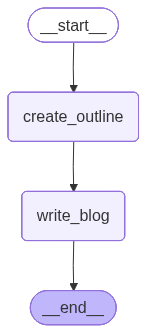

In [8]:
# compile the graph
workflow = graph.compile()
workflow

In [9]:
# execute the graph

initial_state = {"title": "The future of AI in healthcare"}

final_state = workflow.invoke(initial_state)

print("Title -> " + final_state['title'])
print("Outline -> " + final_state['outline'])
print("Blog Post -> " + final_state['content'])

Title -> The future of AI in healthcare
Outline -> **Outline for Blog: The Future of AI in Healthcare**

**I. Introduction**  
   A. Hook: The transformative potential of AI in revolutionizing healthcare.  
   B. Brief overview of current AI applications in healthcare.  
   C. Thesis statement: Exploring how AI will shape the future of healthcare, from patient care to operational efficiency, and the challenges it must overcome.

**II. Current State of AI in Healthcare**  
   A. Diagnostic tools and medical imaging (e.g., AI-powered radiology, pathology).  
   B. Personalized medicine and genomics.  
   C. Virtual health assistants and chatbots.  
   D. Administrative tasks (e.g., scheduling, billing, and claims processing).  
   E. Drug discovery and development.  

**III. The Future of AI in Healthcare: Key Trends and Innovations**  
   A. **Enhanced Diagnostics and Early Detection**  
      1. AI-driven predictive analytics for early disease detection.  
      2. Integration of AI wi

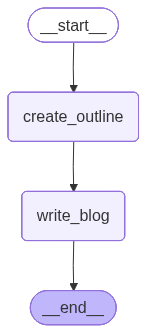

In [10]:
# Visualize Graph
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [11]:
workflow.get_graph().draw_ascii()

'  +-----------+    \r\n  | __start__ |    \r\n  +-----------+    \r\n         *         \r\n         *         \r\n         *         \r\n+----------------+ \r\n| create_outline | \r\n+----------------+ \r\n         *         \r\n         *         \r\n         *         \r\n  +------------+   \r\n  | write_blog |   \r\n  +------------+   \r\n         *         \r\n         *         \r\n         *         \r\n    +---------+    \r\n    | __end__ |    \r\n    +---------+    '